In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Loan_Risk_Working(1).csv")

In [3]:
print(df.head())

   Age   Income  LoanAmount  CreditScore  YearsExperience  Gender  \
0   56  48353.0     31258.0        675.0               20  Female   
1   69  57462.0     23262.0        586.0                6    Male   
2   46  44219.0     26530.0        781.0               26    Male   
3   32  56307.0     11531.0        549.0               11    Male   
4   60  37034.0     27871.0        500.0               19  Female   

     Education           City EmploymentType  LoanApproved  
0  High School        Houston     Unemployed             0  
1  High School  San Francisco  Self-Employed             0  
2          PhD        Houston  Self-Employed             1  
3          NaN       New York     Unemployed             0  
4  High School        Chicago     Unemployed             0  


In [4]:
print("\nshape:")
print(df.shape)


shape:
(5000, 10)


In [5]:
print("\ncolumns:")
print(df.columns)


columns:
Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'YearsExperience',
       'Gender', 'Education', 'City', 'EmploymentType', 'LoanApproved'],
      dtype='str')


In [6]:
print("\ndata type:")
print(df.dtypes)



data type:
Age                  int64
Income             float64
LoanAmount         float64
CreditScore        float64
YearsExperience      int64
Gender                 str
Education              str
City                   str
EmploymentType         str
LoanApproved         int64
dtype: object


In [7]:
print("\ninfo:")
df.info()



info:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              5000 non-null   int64  
 1   Income           4804 non-null   float64
 2   LoanAmount       5000 non-null   float64
 3   CreditScore      4806 non-null   float64
 4   YearsExperience  5000 non-null   int64  
 5   Gender           5000 non-null   str    
 6   Education        4802 non-null   str    
 7   City             5000 non-null   str    
 8   EmploymentType   5000 non-null   str    
 9   LoanApproved     5000 non-null   int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 390.8 KB


In [8]:
print("\nstatistical summary")
print(df.describe())


statistical summary
               Age        Income    LoanAmount  CreditScore  YearsExperience  \
count  5000.000000   4804.000000   5000.000000  4806.000000      5000.000000   
mean     43.584600  49738.123022  19870.768600   575.494590        19.599000   
std      14.919094  15101.361851   8046.542413   160.550839        11.516837   
min      18.000000  -3731.000000 -10059.000000   300.000000         0.000000   
25%      31.000000  39608.500000  14455.250000   433.000000        10.000000   
50%      43.000000  49488.000000  19842.500000   579.000000        20.000000   
75%      56.000000  59917.000000  25326.750000   712.000000        29.000000   
max      69.000000  99146.000000  48353.000000   849.000000        39.000000   

       LoanApproved  
count   5000.000000  
mean       0.230200  
std        0.421003  
min        0.000000  
25%        0.000000  
50%        0.000000  
75%        0.000000  
max        1.000000  


In [9]:

print("\n missing value:")
print(df.isnull().sum())


 missing value:
Age                  0
Income             196
LoanAmount           0
CreditScore        194
YearsExperience      0
Gender               0
Education          198
City                 0
EmploymentType       0
LoanApproved         0
dtype: int64


In [10]:
missing = df.isnull().sum()
missing_percentage = (missing / len(df)) * 100
print("Missing Percentage:")
print(missing_percentage)

Missing Percentage:
Age                0.00
Income             3.92
LoanAmount         0.00
CreditScore        3.88
YearsExperience    0.00
Gender             0.00
Education          3.96
City               0.00
EmploymentType     0.00
LoanApproved       0.00
dtype: float64


In [11]:
print("\nduplicate values:")
print(df.duplicated().sum())


duplicate values:
0


In [12]:
print("\nunique values in Gender:")
print(df["Gender"].unique())


unique values in Gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [13]:
print("\nunique values in Education:")
print(df["Education"].unique())



unique values in Education:
<StringArray>
['High School', 'PhD', nan, 'Masters', 'Bachelors']
Length: 5, dtype: str


In [14]:
print("\nunique values in EmploymentType:")
print(df["EmploymentType"].unique())



unique values in EmploymentType:
<StringArray>
['Unemployed', 'Self-Employed', 'Salaried']
Length: 3, dtype: str


In [15]:
print("\nunique values in LoanApproved:")
print(df["LoanApproved"].unique())


unique values in LoanApproved:
[0 1]


In [16]:
#Data Cleaning

df["Income"] = df["Income"].fillna(df["Income"].median())
df["CreditScore"] = df["CreditScore"].fillna(df["CreditScore"].median())
df["Education"] = df["Education"].fillna(df["Education"].mode()[0])

In [17]:
print("\nmissing value after cleaning:")
print(df.isnull().sum())


missing value after cleaning:
Age                0
Income             0
LoanAmount         0
CreditScore        0
YearsExperience    0
Gender             0
Education          0
City               0
EmploymentType     0
LoanApproved       0
dtype: int64


In [18]:
print("\nEducation Values After Cleaning:")
print(df["Education"].unique())


Education Values After Cleaning:
<StringArray>
['High School', 'PhD', 'Bachelors', 'Masters']
Length: 4, dtype: str


In [19]:
df.to_csv("cleaned_loan_data.csv", index=False)
print("\nCleaned dataset saved successfully!")


Cleaned dataset saved successfully!


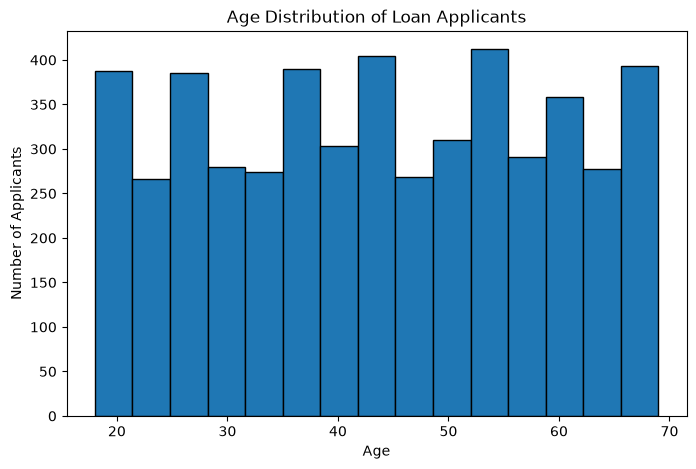

In [20]:
#Age Distribution

plt.figure(figsize=(8,5))
plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Age Distribution of Loan Applicants")
plt.xlabel("Age")
plt.ylabel("Number of Applicants")
plt.show()

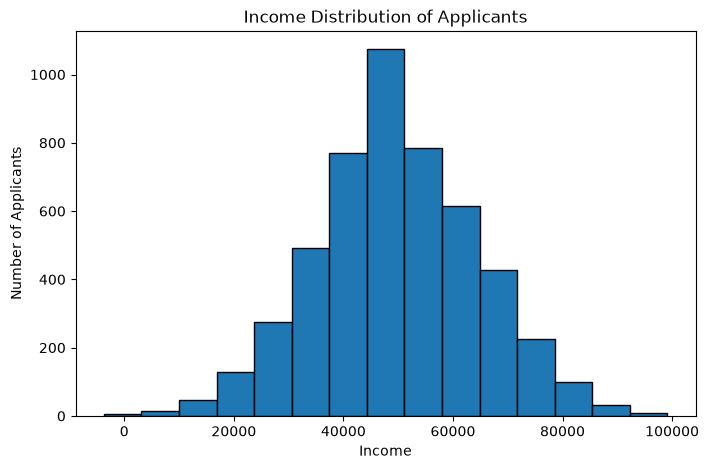

In [21]:

plt.figure(figsize=(8,5))
plt.hist(df["Income"], bins=15, edgecolor="black")
plt.title("Income Distribution of Applicants")
plt.xlabel("Income")
plt.ylabel("Number of Applicants")
plt.show()

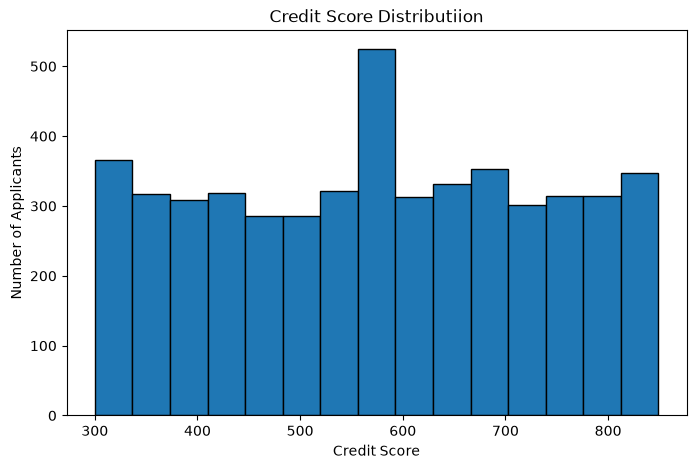

In [22]:
plt.figure(figsize=(8,5))
plt.hist(df["CreditScore"], bins=15, edgecolor="black")
plt.title("Credit Score Distributiion")
plt.xlabel("Credit Score")
plt.ylabel("Number of Applicants")
plt.show()

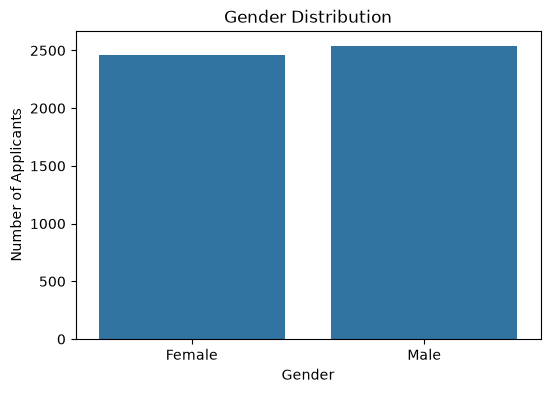

In [23]:
plt.figure(figsize=(6,4))
sns.countplot(x="Gender", data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()

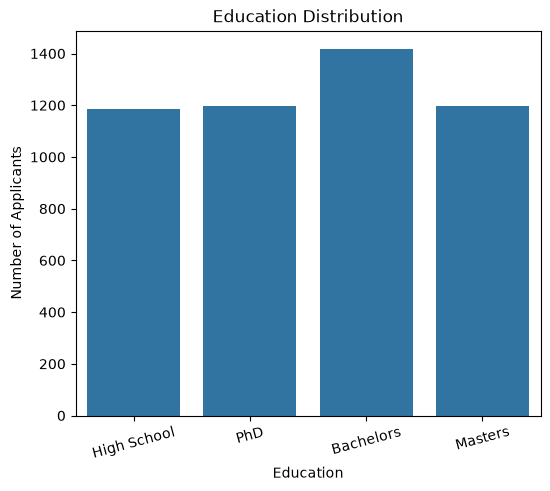

In [24]:
plt.figure(figsize=(6,5))
sns.countplot(x="Education",data=df)
plt.title("Education Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.xticks(rotation = 15)
plt.show()

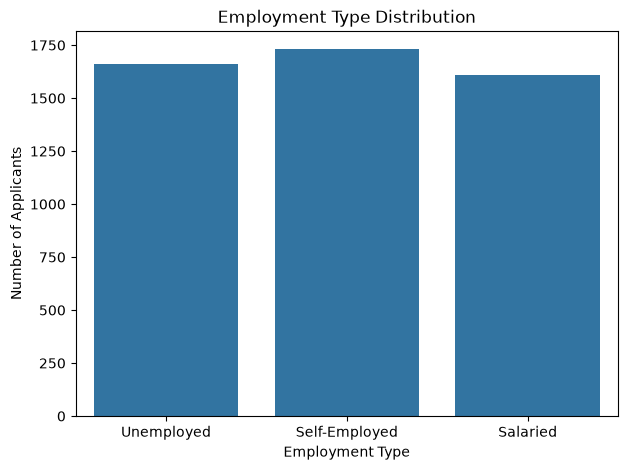

In [25]:
plt.figure(figsize=(7,5))
sns.countplot(x="EmploymentType", data=df)
plt.title("Employment Type Distribution")
plt.xlabel("Employment Type")
plt.ylabel("Number of Applicants")
plt.show()

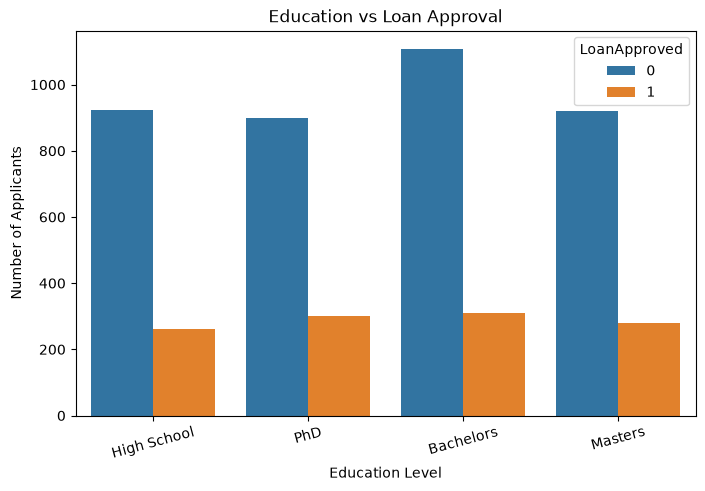

In [26]:
plt.figure(figsize=(8,5))
sns.countplot(x="Education", hue="LoanApproved", data=df)
plt.title("Education vs Loan Approval")
plt.xlabel("Education Level")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=15)
plt.show()

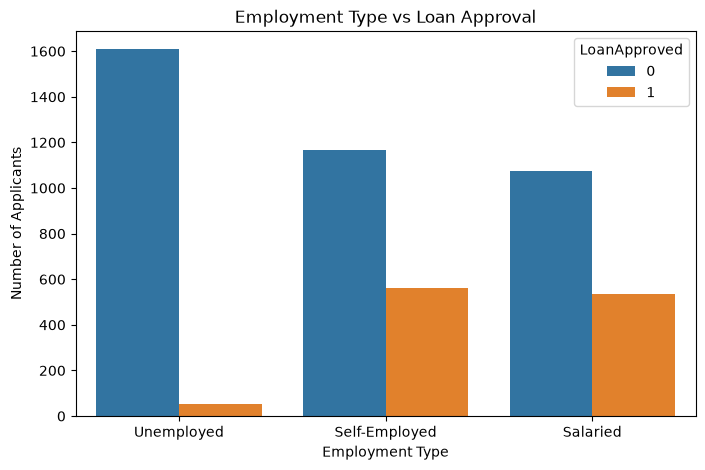

In [27]:
plt.figure(figsize=(8,5))
sns.countplot(x="EmploymentType", hue="LoanApproved", data=df)
plt.title("Employment Type vs Loan Approval")
plt.xlabel("Employment Type")
plt.ylabel("Number of Applicants")
plt.show()

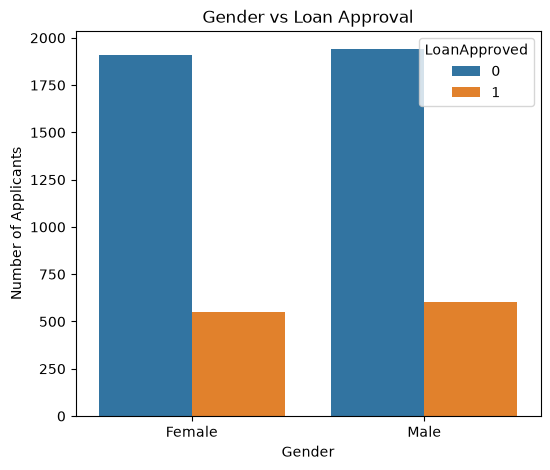

In [28]:
plt.figure(figsize=(6,5))
sns.countplot(x="Gender", hue="LoanApproved", data=df)
plt.title("Gender vs Loan Approval")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()

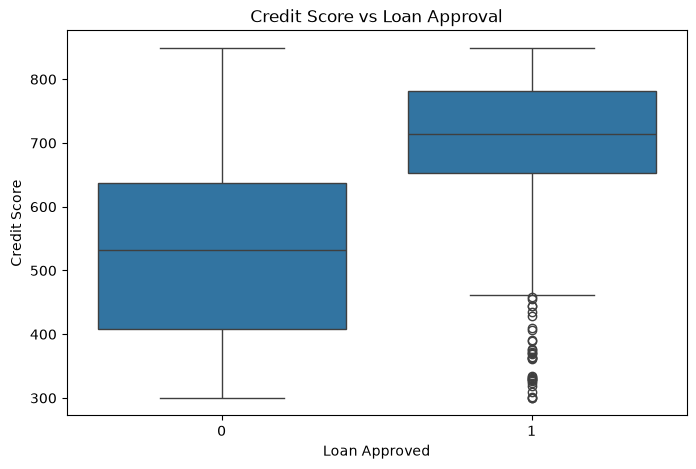

In [29]:
plt.figure(figsize=(8,5))
sns.boxplot(x="LoanApproved", y="CreditScore", data=df)
plt.title("Credit Score vs Loan Approval")
plt.xlabel("Loan Approved")
plt.ylabel("Credit Score")
plt.show()


In [30]:
df.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'YearsExperience',
       'Gender', 'Education', 'City', 'EmploymentType', 'LoanApproved'],
      dtype='str')

In [31]:
encoded_df=df.drop(columns=['City', 'Age','YearsExperience','Education','Gender'],inplace= True)


In [32]:
encoded_df

In [33]:
from sklearn.preprocessing import OneHotEncoder

encoded_df= pd.get_dummies(df, columns=['EmploymentType'], dtype= int)
# from sklearn.preprocessing import LabelEncoder
# le= LabelEncoder()
# encoded_df=le.fit_transform(encoded_df)


In [34]:
correlation= encoded_df.corr(numeric_only=True)
correlation
# plt.figure(figsize=(7,7))
# sns.heatmap(correlation, annot= True,linewidths=0.5)

,Income,LoanAmount,CreditScore,LoanApproved,EmploymentType_Salaried,EmploymentType_Self-Employed,EmploymentType_Unemployed
Income,1.000000,0.002611,-0.047993,0.186923,0.002613,-0.000733,-0.001852
LoanAmount,0.002611,1.000000,0.003603,0.018302,0.017415,-0.023593,0.006553
CreditScore,-0.047993,0.003603,1.000000,0.460991,0.003146,-0.002743,-0.000350
LoanApproved,0.186923,0.018302,0.460991,1.000000,0.168160,0.164550,-0.333057
EmploymentType_Salaried,0.002613,0.017415,0.003146,0.168160,1.000000,-0.501259,-0.485841
EmploymentType_Self-Employed,-0.000733,-0.023593,-0.002743,0.164550,-0.501259,1.000000,-0.512779
EmploymentType_Unemployed,-0.001852,0.006553,-0.000350,-0.333057,-0.485841,-0.512779,1.000000


In [35]:
# Income  CreditScore  EmploymentType_Salaried  EmploymentType_Self-Employed  EmploymentType_Unemployed

# Age  YearsExperience

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X=encoded_df.drop(columns=['LoanApproved']) 
y= encoded_df['LoanApproved']

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

In [39]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

model.fit(X_train, y_train)

/home/amanarayanyadav/jupyter-env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [40]:
y_pred = model.predict(X_test)

print("Actual values:", y_test.tolist())
print("Predicted values:", y_pred.tolist())

Actual values: [0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.883
Confusion Matrix:
[[719  51]
 [ 66 164]]
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       770
           1       0.76      0.71      0.74       230

    accuracy                           0.88      1000
   macro avg       0.84      0.82      0.83      1000
weighted avg       0.88      0.88      0.88      1000



## Local Web App Deployment (Added — original notebook cells above are unchanged)

The files `app.py`, `templates/index.html`, and the launch scripts provide a local Flask web interface. Run `run_windows.bat` on Windows, or `run_mac_linux.sh` on macOS/Linux. The web app trains from the included CSV if no exported model is present.

Optional: after running the original model-training cells above, run the next cell to export that notebook model.

In [ ]:
# Optional deployment export cell (added; does not alter the original model-training code)
import os
import joblib

os.makedirs('artifacts', exist_ok=True)
joblib.dump(
    {'model': model, 'feature_columns': list(X.columns)},
    'artifacts/loan_model.joblib'
)
print('Model exported to artifacts/loan_model.joblib')